In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Shared helpers (paths, TE00 Delta_k, chirped grating, grating spectrum, FWHM) live in qpm_tools.py next to this notebook.
# autoreload picks up edits to it without restarting the kernel.
%load_ext autoreload
%autoreload 2
from qpm_tools import (ROOT_PREFIX, SWEEP_MATSUDA, SWEEP_NANOLN, delta_k_for_geom, lam_FH_at_delta_k,
                       chirped_domain_edges, make_chirped_chi2_lookup, generate_chirped_chi2_norm,
                       qpm_spectrum_fft, qpm_spectrum_exact, fwhm)

print("ROOT_PREFIX:", ROOT_PREFIX)

ROOT_PREFIX: /Users/sagardoshi/


In [2]:
TICK_FS = 20
LABEL_FS = 22
LEGEND_FS = 17

In [16]:
# Mode-solver sweep used for Delta_k(lambda) (folders defined in qpm_tools.py)
# MODE_DATA_SWEEP = SWEEP_MATSUDA # Matsuda
MODE_DATA_SWEEP = SWEEP_NANOLN    # Perturbed Matsuda - NanoLN sample

# Nominal waveguide geometry for Delta_k(lambda): must be a (t_LN, W) point of MODE_DATA_SWEEP
T_LN_NM = 400
W_WG_NM = 1800

FH_RANGE_NM  = (800, 2000) # FH window for Delta_k (the sweep solved 400-2000nm, so SH >= 400nm -> FH >= 800nm)
DLAM_FINE_NM = 0.1         # Fine FH grid that the 10nm-spaced solver data is splined onto

#### Plot the QPM pattern: $± χ^{(2)} = ± \ 1$

In [17]:
# Plot the QPM pattern
devID = "DEV48_1.8"
devNUM = 48
L_pol_um = 12000 # 12 mm
print(f"L_pol_um = {L_pol_um:.1f}um")
chirp_pp_start_um = 3.250
chirp_pp_end_um = 3.450

z_qpm_pattern_um = np.arange(0, L_pol_um, 0.1) # 100nm steps
z_qpm_pattern_mm = z_qpm_pattern_um * 1e-3 # [mm] convert to mm for plotting
z_qpm_pattern_m  = z_qpm_pattern_um * 1e-6 # [m] convert to m for QPM function
print(f"{len(z_qpm_pattern_um)} points in QPM pattern from 0 to {L_pol_um:.1f}um")

L_pol_um = 12000.0um
120000 points in QPM pattern from 0 to 12000.0um


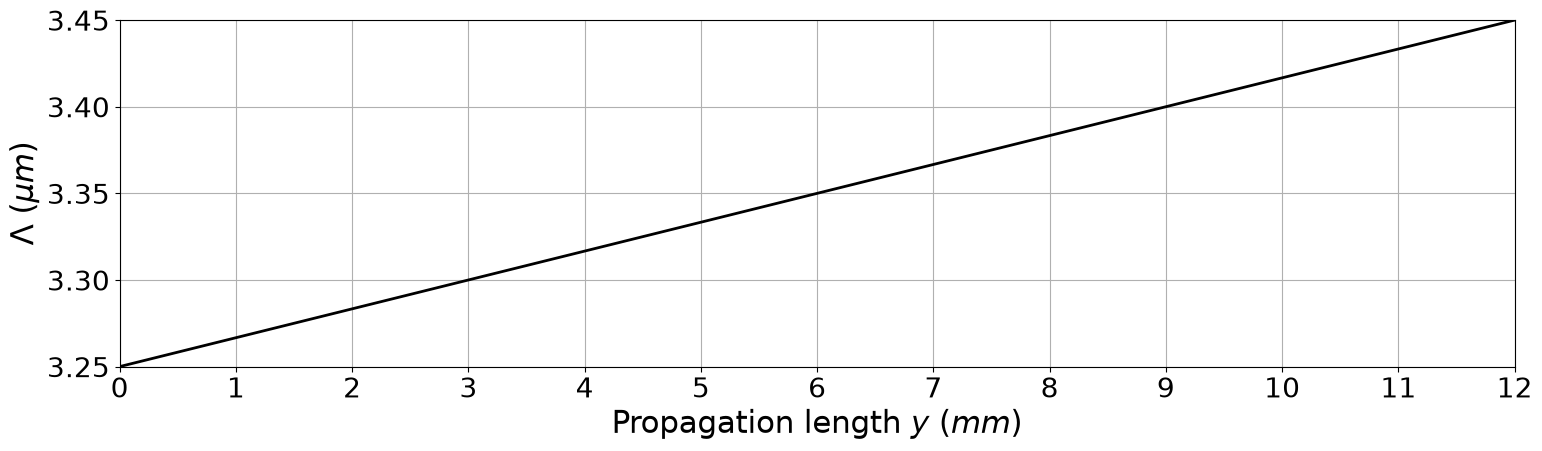

In [18]:
local_pp = np.interp(z_qpm_pattern_um, [0, L_pol_um], [chirp_pp_start_um, chirp_pp_end_um])

fig, ax = plt.subplots(1, 1, figsize=(18, 4.5))

ax.plot(z_qpm_pattern_mm, local_pp, linewidth=2.0, color='k')
ax.set_ylabel(r'$\Lambda \ (μ m)$', fontsize=LABEL_FS)
ax.set_xlabel(r'Propagation length $y \ (mm)$', fontsize=LABEL_FS)

ymin, ymax = chirp_pp_start_um, chirp_pp_end_um
ax.set_yticks(np.arange(ymin, ymax + 0.05, 0.05))
ax.set_ylim(ymin, ymax)

xmin, xmax = 0.0, L_pol_um*1e-3
ax.set_xticks(np.arange(xmin, xmax + 1.0, 1.0))
ax.set_xlim(xmin, xmax)

ax.grid(True, 'both',  linestyle='-', alpha=1.0)

ax.tick_params(axis='both', which='major', labelsize=TICK_FS)

Lookup matches the layout function on the 120000-pt grid: True


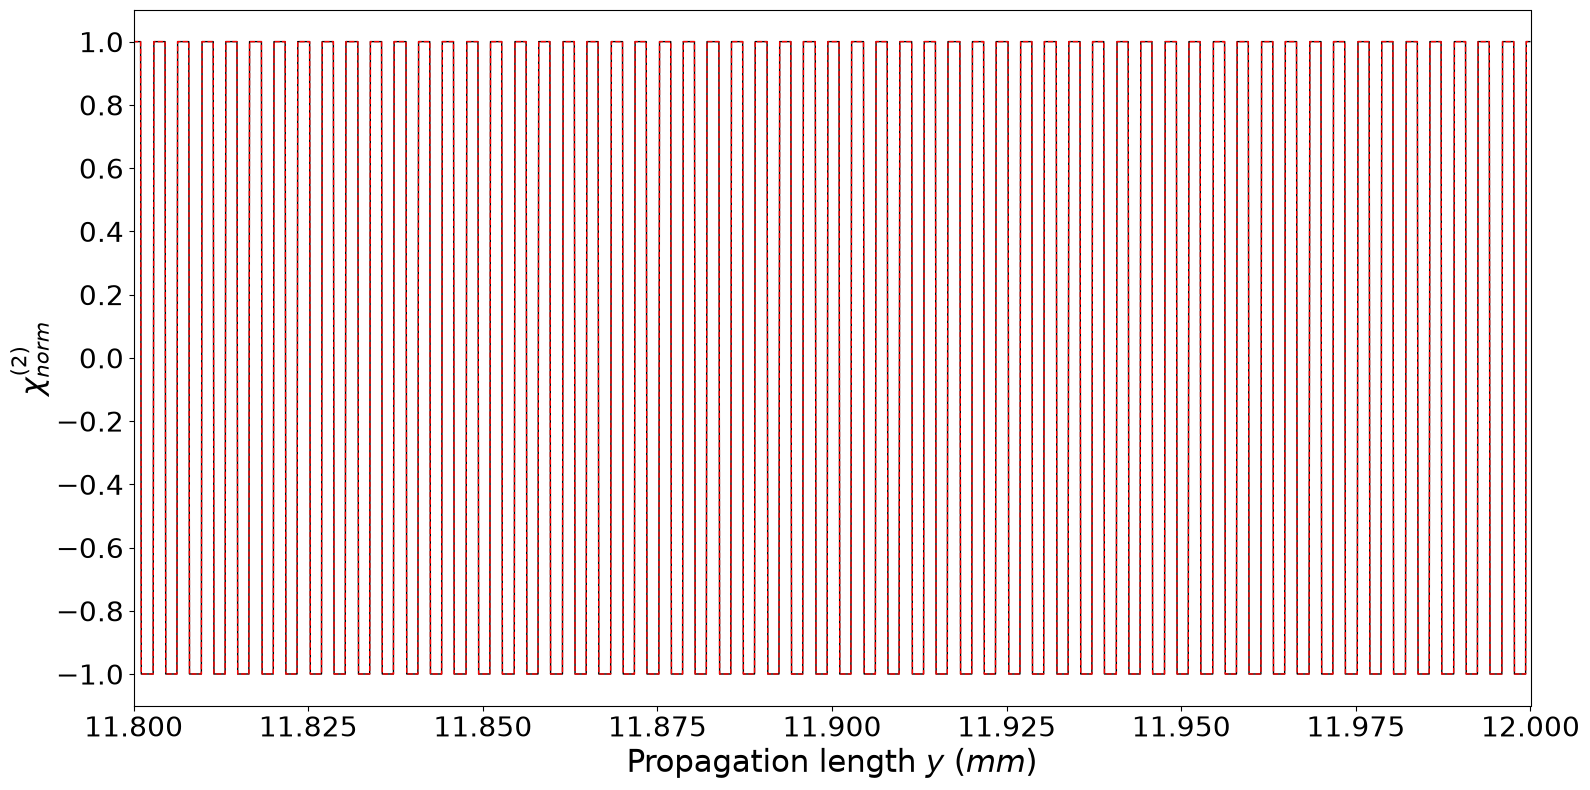

In [19]:
qpm                      = make_chirped_chi2_lookup(L_pol_um, chirp_pp_start_um, chirp_pp_end_um)                     # Callable that maps z [m] -> χ^(2) normalized (+-1)
qpm_layout_func_computed = generate_chirped_chi2_norm(z_qpm_pattern_um, L_pol_um, chirp_pp_start_um, chirp_pp_end_um) # Verify that new function exactly matches layout code.

print(f"Lookup matches the layout function on the {len(z_qpm_pattern_um)}-pt grid: "
      f"{np.array_equal(qpm(z_qpm_pattern_m), qpm_layout_func_computed)}")

fig, ax = plt.subplots(1, 1, figsize=(16, 8))

ax.plot(z_qpm_pattern_mm, qpm(z_qpm_pattern_m), linewidth=1.0, color='k')
ax.plot(z_qpm_pattern_mm, qpm_layout_func_computed, linewidth=1.0, color='r', linestyle='--', label='Computed QPM layout')

xmin, xmax = 11.8, 12.0
ax.set_xlim(xmin, xmax)

ymin, ymax = -1.0, 1.0
yticks = np.arange(ymin, ymax + 0.1, 0.2)
ax.set_ylim(ymin-0.1, ymax+0.1)
ax.set_yticks(yticks)

ax.set_ylabel(r'$\chi^{(2)}_{norm}$', fontsize=LABEL_FS)
ax.set_xlabel(r'Propagation length $y \ (mm)$', fontsize=LABEL_FS)
ax.tick_params(axis='both', which='major', labelsize=TICK_FS)

plt.tight_layout()
plt.show()

#### Calculate and plot the fourier amplitude of the QPM grating vs. phase matching condition

In [20]:
# Grating spectrum |G(Delta_k)|^2, G = (1/L) int g(z) exp(-i Delta_k z) dz, so |G| = d_eff/d33 (uniform grating: (2/pi)^2 = 0.405).
# dz = 10nm: the domain walls aren't on the grid, so each wall lands within dz of its true position. That error, not the FFT
#   settings, is what limits the accuracy (~0.5% of the peak; the exact cross-check below prints it).
# Zero padding only interpolates the spectrum; the true resolution is 2pi/L = 5.2e-4 rad/um. PAD_FACTOR = 4 gives a 7.5e-5 rad/um
#   step and the same FWHM to 1e-5 as 32 (which needed a 2^26-pt, ~1GB FFT).
DZ_FFT_UM  = 0.010
PAD_FACTOR = 4

z_fft_um = np.arange(0, L_pol_um, DZ_FFT_UM)
delta_k_grating, grating_power = qpm_spectrum_fft(qpm(z_fft_um * 1e-6), DZ_FFT_UM, pad_factor=PAD_FACTOR)
print(f"{len(z_fft_um)} z points, Delta_k step = {delta_k_grating[1]:.2e} rad/um")

# The chirp's K = 2pi/Lambda band, and the ideal flat-top level of a linear chirp, for reference
K_CHIRP = np.sort(2*np.pi / np.array([chirp_pp_start_um, chirp_pp_end_um])) # [rad/um]
print(f"Chirp K band: {K_CHIRP[0]:.5f} - {K_CHIRP[1]:.5f} rad/um (width {np.diff(K_CHIRP)[0]:.5f}), "
      f"ideal plateau (2/pi)^2 * 2pi/(L dK) = {(2/np.pi)**2 * 2*np.pi / (L_pol_um*np.diff(K_CHIRP)[0]):.5f}")

# Cross-check against the exact transform of the domain edges (no z grid), around the band
edges_um, signs = chirped_domain_edges(L_pol_um, chirp_pp_start_um, chirp_pp_end_um)
check = (delta_k_grating > K_CHIRP[0] - 0.05) & (delta_k_grating < K_CHIRP[1] + 0.05)
grating_power_exact = qpm_spectrum_exact(edges_um, signs, L_pol_um, delta_k_grating[check])
print(f"FFT vs exact: max |diff| = {np.max(np.abs(grating_power[check] - grating_power_exact)):.2e} "
      f"(peak {grating_power_exact.max():.2e})")

1200000 z points, Delta_k step = 7.49e-05 rad/um
Chirp K band: 1.82121 - 1.93329 rad/um (width 0.11207), ideal plateau (2/pi)^2 * 2pi/(L dK) = 0.00189
FFT vs exact: max |diff| = 1.25e-05 (peak 2.78e-03)


Delta_k from tLN400_etch400_w1800_sw70_clad1350nmSiO2_modes.csv
plateau level = 0.00217, half max = 0.00108
crossings     = 1.82339, 1.93082 rad/um  (Lambda = 3.2542 - 3.4459 um)
FWHM          = 0.10742 rad/um
FH range      = 1378.2 - 1538.7 nm  (160.5 nm wide)
SH range      = 689.1 - 769.3 nm  (80.3 nm wide)


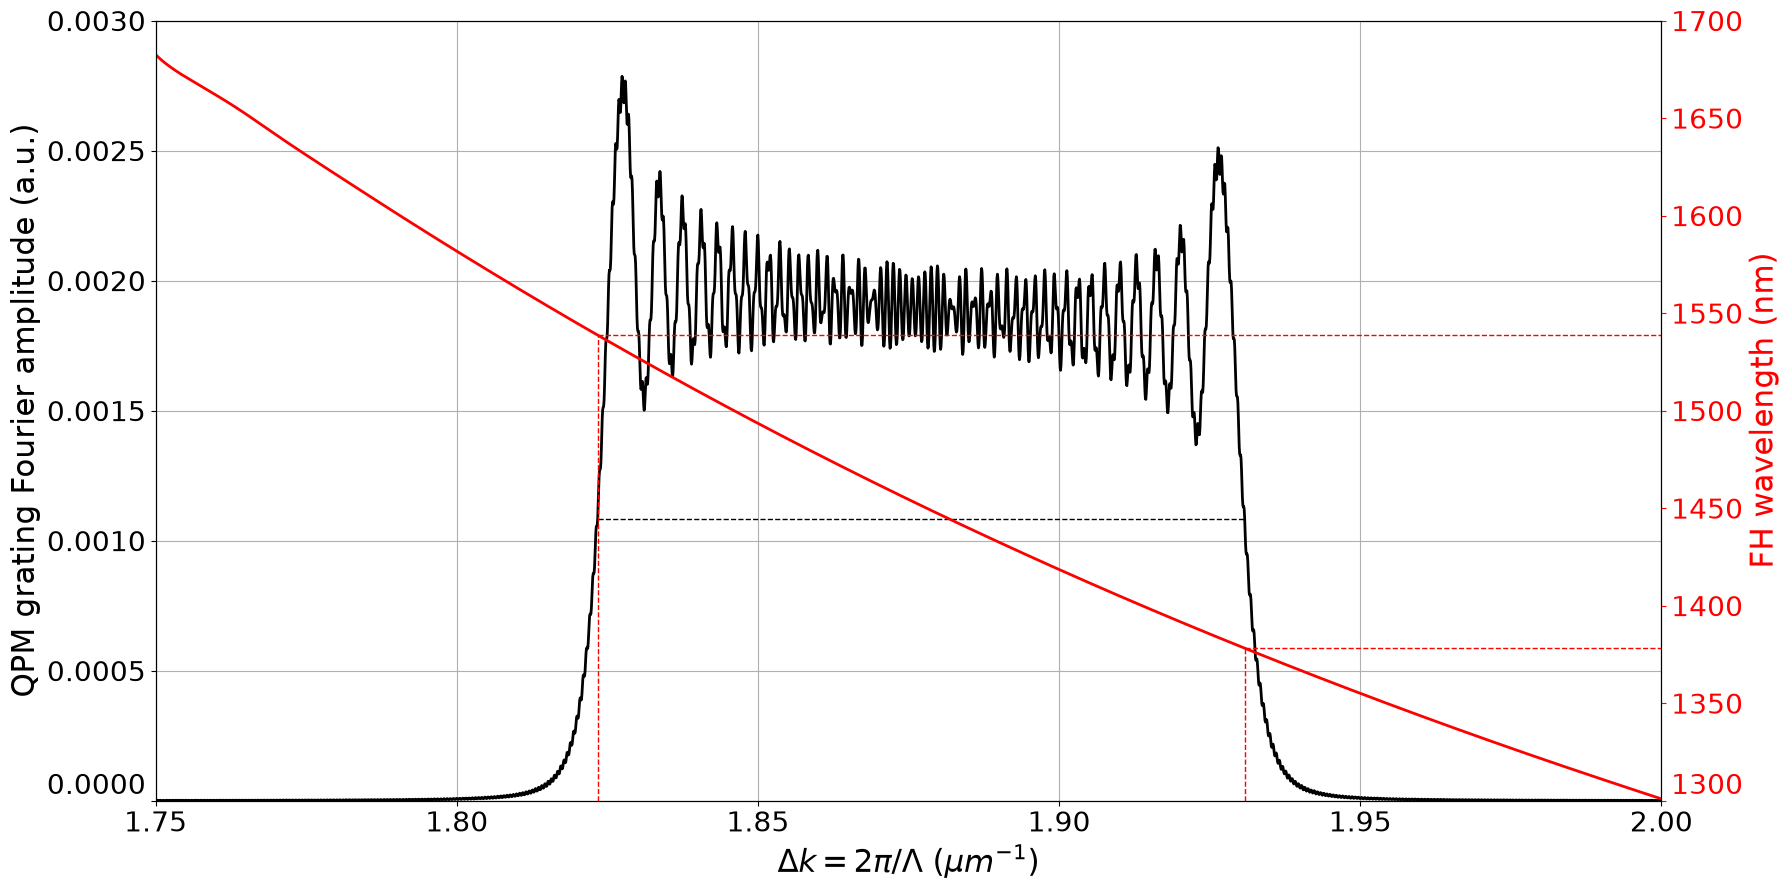

In [22]:
# Delta_k(lambda_FH) for the nominal geometry (TE00 -> TE00, k_SH - 2k_FH)
lam_FH_fine_nm = np.round(np.arange(FH_RANGE_NM[0], FH_RANGE_NM[1] + DLAM_FINE_NM/2, DLAM_FINE_NM), 6) # round off arange float drift
delta_k_nom, modes_fpath = delta_k_for_geom(T_LN_NM, W_WG_NM, MODE_DATA_SWEEP, lam_FH_fine_nm)
print(f"Delta_k from {os.path.basename(modes_fpath)}")

# FWHM of the grating spectrum. 'plateau' = half of the median of the top 10% of samples in the window (rippled flat top),
# so the level shifts a little with the window: moving the window edges by a few 0.01 rad/um changes the FWHM by ~0.5%.
FWHM_WINDOW = (K_CHIRP[0] - 0.05, K_CHIRP[1] + 0.05) # [rad/um]
width, xL, xR, top, half = fwhm(delta_k_grating, grating_power, window=FWHM_WINDOW, level_from='plateau')

# Delta_k decreases with wavelength, so the low-Delta_k crossing xL is the long-wavelength edge
lam_FH_xL, lam_FH_xR = lam_FH_at_delta_k(delta_k_nom, lam_FH_fine_nm, [xL, xR])
lam_FH_min, lam_FH_max = lam_FH_xR, lam_FH_xL

print(f"plateau level = {top:.5f}, half max = {half:.5f}")
print(f"crossings     = {xL:.5f}, {xR:.5f} rad/um  (Lambda = {2*np.pi/xR:.4f} - {2*np.pi/xL:.4f} um)")
print(f"FWHM          = {width:.5f} rad/um")
print(f"FH range      = {lam_FH_min:.1f} - {lam_FH_max:.1f} nm  ({lam_FH_max - lam_FH_min:.1f} nm wide)")
print(f"SH range      = {lam_FH_min/2:.1f} - {lam_FH_max/2:.1f} nm  ({(lam_FH_max - lam_FH_min)/2:.1f} nm wide)")

# ---- Plot ----
fig, ax = plt.subplots(1, 1, figsize=(18, 9))

xmin, xmax, xstep = 1.75, 2.00, 0.05
ax.plot(delta_k_grating, grating_power, color='k', linewidth=2.0, label='QPM grating')
ax.hlines(half, xmin=xL, xmax=xR, color='k', linestyle='--', linewidth=1.0)

ax.set_xlabel(r'$\Delta k = 2\pi/\Lambda \ (μm^{-1})$', fontsize=LABEL_FS)
# ax.set_ylabel(r'QPM grating Fourier amplitude $|G(\Delta k)|^2$', fontsize=LABEL_FS)
ax.set_ylabel(f'QPM grating Fourier amplitude (a.u.)', fontsize=LABEL_FS)
ax.tick_params('both', labelsize=TICK_FS)

ymin, ymax = 0.0, 0.003
ax.set_yticks(np.arange(ymin, ymax + 0.00025, 0.0005))
ax.set_ylim(ymin, ymax)
ax.set_xticks(np.arange(xmin, xmax + xstep/2.0, xstep))
ax.set_xlim(xmin, xmax)
ax.grid(True, 'both', linestyle='-', alpha=1.0)

# Delta_k(lambda) on the right axis: Delta_k along x (shared with the grating), FH wavelength up the right axis
ax2 = ax.twinx()
ax2.plot(delta_k_nom, lam_FH_fine_nm, color='red', linewidth=2.0,
         label=rf'$\Delta k(\lambda_{{FH}})$, TE00$\rightarrow$TE00, $t_{{LN}}$ = {T_LN_NM}nm, $W$ = {W_WG_NM/1000:.2f}μm')

lam_step = 50
lam_at_xlim = lam_FH_at_delta_k(delta_k_nom, lam_FH_fine_nm, [xmax, xmin]) # Wavelengths at the x-axis ends
ymin2, ymax2 = lam_step*np.floor(np.nanmin(lam_at_xlim)/lam_step), lam_step*np.ceil(np.nanmax(lam_at_xlim)/lam_step)
ax2.set_yticks(np.arange(ymin2, ymax2 + lam_step/2.0, lam_step))
ax2.set_ylim(ymin2, ymax2)
ax2.set_ylabel('FH wavelength (nm)', fontsize=LABEL_FS, color='red')
ax2.tick_params('y', labelsize=TICK_FS, colors='red')

# FWHM crossings: up from each half-max point to the Delta_k curve, then across to the wavelength axis
for x, lam in zip([xL, xR], [lam_FH_xL, lam_FH_xR]):
    ax2.vlines(x, ymin=ymin2, ymax=lam, color='red', linestyle='--', linewidth=1.0)
    ax2.hlines(lam, xmin=x, xmax=xmax, color='red', linestyle='--', linewidth=1.0)
    # ax2.annotate(f'{lam:.1f} nm', xy=(xmax, lam), xytext=(-6, 4), textcoords='offset points',
    #              ha='right', va='bottom', color='red', fontsize=TICK_FS)

handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
# ax.legend(handles=handles, fontsize=LEGEND_FS, loc='upper left')

# ax.set_title(f"Chirp {chirp_pp_start_um}-{chirp_pp_end_um}μm over {L_pol_um/1000:.0f}mm: "
#              f"FWHM -> FH {lam_FH_min:.1f}-{lam_FH_max:.1f}nm, SH {lam_FH_min/2:.1f}-{lam_FH_max/2:.1f}nm", fontsize=LABEL_FS)

# Lift the lowest y tick labels (0.0000 / 1300) above the axis corner so they don't collide with the x tick labels
plt.setp(ax.get_yticklabels()[0],  va='bottom')
plt.setp(ax2.get_yticklabels()[0], va='bottom')

plt.tight_layout()
plt.show()